# Morse-Smale complex (MSC) graph barycenter (λ-converge)

Compute a (partial) Fused Gromov–Wasserstein barycenter for a family of **Morse-Smale complexes** loaded from `./data/`, using **adjacency** (or shortest-path / heat-kernel) relation matrices.

This notebook mirrors the demo pipeline in `graph_barycenter_adjacency.ipynb`, but replaces synthetic graph generation with MSC files (`treeNodes_*.txt` / `treeEdges_*.txt`) via `lib/graph_reader.py`.

**Pipeline**
1. Select MSC snapshots (mesh indices) from `./data/`.
2. Load each complex as a `networkx.Graph` (`read_morse_graph_txt`), merging duplicate boundary nodes by `(x,y,z)`.
3. Verify connectivity of loaded graphs.
4. Subsample along Morse paths between critical points (critical nodes always kept).
5. Visualize processed graphs in the `(x, y)` plane from file coordinates.
6. Diagnose same-type pairwise feature costs among critical nodes (normalized Euclidean\(^2\) + scalar\(^2\)) with shared-axis histograms per input \(\times\) type and per-type aggregates; set \(\texttt{type_scale}=\sqrt{p/2}\) from the lowest aggregated \(x\)-percentile so a type mismatch costs \(p\).
7. Build shortest-path relation matrices (normalized) and node features `(x,y,z)` + normalized scalar + critical-point type for FGW.
8. Choose a seed network (specified index, or the input with minimum sum of PFGW distances to the others); apply `exclude_seed` / `expand_to_largest`. Expansion reinserts nodes dropped during subsampling (longest-edge midpoint splits) without changing input graph sizes. Node masses \(p_i\) and \(p\) are the discretized arc-length measure (total mass 1).
9. Run partial FGW (PFGW) barycenter with geometric λ decay (`lambda_converge`): start at `lambda_init` (default 1.0), decay toward `lambda_target` over `decay_steps`, and warm-start each step from the previous `(X_center, C_center, T)`.
10. Drop barycenter nodes without substantial couplings to every input.
11. Reconstruct and visualize the barycenter graph; save the **complete** (pre-threshold) barycenter bundle under `results/barycenters/<keyword>_lambda_converge_<mm-dd-yyyy-hh-mm-ss>/` with all computation parameters in `meta.json`.
12. Color transfer onto input graphs via PFGW couplings.

This notebook is an alternative to `msc_barycenter_shortestpath.ipynb`. All saved artifacts use the `lambda_converge` keyword plus a save-time stamp so they stay distinct from the general pipeline and from later reruns. Downstream evaluation / sparsification lives in `msc_barycenter_evaluation.ipynb` (point it at a `*_lambda_converge_*` bundle). Use `msc_barycenter_bundle_inspect.ipynb` to list saved runs and review every recorded parameter.


In [1]:
print("hello world")

hello world


In [2]:
# Imports (re-run this cell after editing files under lib/ — no kernel restart needed)
import importlib
import os
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import ot

import lib.graph_reader as graph_reader
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter
import lib.msc_plotting as msc_plotting
import lib.msc_color_transfer as msc_color_transfer
import lib.msc_barycenter_threshold as msc_barycenter_threshold
import lib.barycenter_io as barycenter_io
import lib.msc_barycenter_eval as msc_barycenter_eval
import lib.measure_network as measure_network

importlib.reload(graph_reader)
importlib.reload(gromov)
importlib.reload(gromov_barycenter)
importlib.reload(msc_barycenter_threshold)
importlib.reload(msc_plotting)
importlib.reload(msc_color_transfer)
importlib.reload(barycenter_io)
importlib.reload(msc_barycenter_eval)
importlib.reload(measure_network)

from lib.graph_reader import (
    read_morse_graph_txt,
    load_morse_graphs,
    prepare_graph_for_barycenter,
    summarize_graph_connectivity,
    merge_duplicate_nodes,
    sample_morse_graph,
    expand_sampled_graph_to_size,
    relation_matrix,
    compute_relation_rescale,
    apply_relation_scaling,
    reconstruct_msc_barycenter_mst_graph,
    node_height,
    msc_node_visual_type,
    draw_msc_nodes,
    msc_xy_positions,
    draw_processed_msc_graphs,
    draw_msc_graphs_overlay,
    barycenter_xy_positions,
    set_barycenter_axes_limits,
    draw_msc_barycenter_graph,
    draw_barycenter_thresholded_complete,
    draw_barycenter_colormap,
    build_complete_barycenter_graph,
    build_thresholded_barycenter_graph,
    msc_barycenter_weight_euclidean_differences,
    plot_msc_barycenter_weight_euclidean_debug,
)
from lib.msc_color_transfer import (
    DEFAULT_CORNER_COLORS,
    compute_barycenter_node_colors,
    transfer_barycenter_colors_to_inputs,
    draw_input_graph_coupling_colors,
)
from lib.barycenter_io import (
    save_barycenter_bundle,
    default_barycenter_outdir,
    timestamped_barycenter_outdir,
    barycenter_save_timestamp,
    build_barycenter_run_meta,
)
from lib.msc_barycenter_eval import (
    pfgw_total_cost,
    prune_barycenter_nodes_lacking_all_input_support,
    select_seed_by_min_pfgw_sum,
    diagnose_barycenter_morse_types,
)
from ot.utils import dist
from lib.gromov import (
    partial_fused_gromov_ver1,
    partial_gromov_ver1,
    gromov_wasserstein,
    GW_dist,
    PGW_dist_with_penalty,
    PFGW_dist_with_penalty,
)
from lib.gromov_barycenter import (
    pfgw_barycenters,
    pfgw_barycenters_lambda_converge,
    lambda_decay_schedule,
)
from lib.measure_network import (
    arc_length_node_measure,
    duplicate_measure_nodes,
    split_measure_nodes,
)


In [3]:
# --- MSC data configuration ---
DATA_ROOT = Path("data")
DATA_KEYWORD = "VortexStreet"
# DATA_KEYWORD = "synthetic"

# Default demo: VortexStreet MSC snapshots (edit mesh_ids / folder as needed)
MSC_DIR = DATA_ROOT / DATA_KEYWORD / "MSC_1.0"
mesh_ids = [146, 147, 148, 149, 150]  # five nearby time steps

# MSC_DIR = DATA_ROOT / DATA_KEYWORD / "DESC-MC_0.0"
# mesh_ids = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


_MSC_NODE_PATTERNS = (
    ("treeNodes_monoMesh_{mesh_id}.txt", "treeEdges_monoMesh_{mesh_id}.txt"),
    ("treeNodes_synthetic_noise_{mesh_id:02d}.txt", "treeEdges_synthetic_noise_{mesh_id:02d}.txt"),
)
_MSC_ID_PATTERNS = (
    re.compile(r"treeNodes_monoMesh_(\d+)\.txt$"),
    re.compile(r"treeNodes_synthetic_noise_(\d+)\.txt$"),
)


def msc_paths(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Return (node_file, edge_file) for a mesh index.

    Supports monoMesh snapshots (treeNodes_monoMesh_*.txt) and synthetic
    noise datasets (treeNodes_synthetic_noise_*.txt).
    """
    for node_pat, edge_pat in _MSC_NODE_PATTERNS:
        node = msc_dir / node_pat.format(mesh_id=mesh_id)
        edge = msc_dir / edge_pat.format(mesh_id=mesh_id)
        if node.exists() and edge.exists():
            return str(node), str(edge)
    raise FileNotFoundError(f"Missing MSC files for mesh {mesh_id} in {msc_dir}")


def list_mesh_ids(msc_dir: Path = MSC_DIR):
    """Discover available mesh indices from treeNodes_*.txt in msc_dir."""
    ids = []
    seen = set()
    for p in sorted(msc_dir.glob("treeNodes_*.txt")):
        for pat in _MSC_ID_PATTERNS:
            m = pat.search(p.name)
            if m:
                mesh_id = int(m.group(1))
                if mesh_id not in seen:
                    seen.add(mesh_id)
                    ids.append(mesh_id)
                break
    return ids


print("MSC directory:", MSC_DIR.resolve())
print("Available meshes (count):", len(list_mesh_ids()))
print("Using mesh_ids:", mesh_ids)


MSC directory: C:\Users\mingz\desktop\MSCBarycenter\data\VortexStreet\MSC_1.0
Available meshes (count): 157
Using mesh_ids: [146, 147, 148, 149, 150]


In [4]:
def load_msc_nx(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Load one MSC as (nx.Graph, critical_node_ids)."""
    node_f, edge_f = msc_paths(mesh_id, msc_dir)
    G, critical_nodes = read_morse_graph_txt(node_f, edge_f)
    return G, critical_nodes


# prepare_graph_for_barycenter: path sampling along ascending/descending edges
# (see lib/graph_reader.sample_morse_graph); critical nodes are always kept.


# Load raw MSC graphs
raw_graphs = []
critical_lists = []
for mid in mesh_ids:
    G, crit = load_msc_nx(mid)
    raw_graphs.append(G)
    critical_lists.append(crit)
    print(
        f"mesh {mid}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
        f"critical={len(crit)}"
    )

# Connectivity check on loaded (unsampled) graphs
print("\n--- Loaded graph connectivity ---")
raw_connectivity = []
for mid, G, crit in zip(mesh_ids, raw_graphs, critical_lists):
    info = summarize_graph_connectivity(G, label=f"loaded mesh {mid}", critical_nodes=crit)
    raw_connectivity.append(info)


mesh 146: nodes=8223, edges=8311, critical=117
mesh 147: nodes=8189, edges=8277, critical=117
mesh 148: nodes=8089, edges=8175, critical=115
mesh 149: nodes=8087, edges=8171, critical=113
mesh 150: nodes=8073, edges=8157, critical=113

--- Loaded graph connectivity ---
[loaded mesh 146] CONNECTED
  nodes=8223, edges=8311, largest component=8223
  critical nodes (id list): 117 in graph, 117 in largest component
  critical nodes (separatrixType=0): 117
[loaded mesh 147] CONNECTED
  nodes=8189, edges=8277, largest component=8189
  critical nodes (id list): 117 in graph, 117 in largest component
  critical nodes (separatrixType=0): 117
[loaded mesh 148] CONNECTED
  nodes=8089, edges=8175, largest component=8089
  critical nodes (id list): 115 in graph, 115 in largest component
  critical nodes (separatrixType=0): 115
[loaded mesh 149] CONNECTED
  nodes=8087, edges=8171, largest component=8087
  critical nodes (id list): 113 in graph, 113 in largest component
  critical nodes (separatrixTyp

In [5]:
# Graphs used for barycenter (path subsampling between critical points)
# Sampled edges store the original Morse walk as `path_nodes` / `arc_length`
# so seed expansion can reinsert dropped nodes without changing these graphs.

# parameters used for "synthetic"
# SAMPLE_RATE = 0.02      # lower rate -> more nodes along paths (on largest component)
# SAMPLE_MODE = "geo"     # 'step' | 'geo'

# parameters used for "VortexStreet"
SAMPLE_RATE = 10.0       # lower rate -> more nodes along paths (on largest component)
SAMPLE_MODE = "geo"     # 'step' | 'geo'

# 'largest' keeps one connected piece (required for connected subsample); 'full' keeps all components
SAMPLE_COMPONENT = "largest"

Gs = []
critical_lists_sampled = []
for G, crit in zip(raw_graphs, critical_lists):
    H, crit_h = prepare_graph_for_barycenter(
        G,
        critical_nodes=crit,
        rate=SAMPLE_RATE,
        mode=SAMPLE_MODE,
        component=SAMPLE_COMPONENT,
    )
    Gs.append(H)
    critical_lists_sampled.append(crit_h)

print("\n--- Subsampled graph connectivity ---")
for i, G in enumerate(Gs):
    summarize_graph_connectivity(
        G,
        label=f"subsampled mesh {mesh_ids[i]}",
        critical_nodes=critical_lists_sampled[i],
    )



--- Subsampled graph connectivity ---
[subsampled mesh 146] CONNECTED
  nodes=382, edges=470, largest component=382
  critical nodes (id list): 117 in graph, 117 in largest component
  critical nodes (separatrixType=0): 117
[subsampled mesh 147] CONNECTED
  nodes=378, edges=466, largest component=378
  critical nodes (id list): 117 in graph, 117 in largest component
  critical nodes (separatrixType=0): 117
[subsampled mesh 148] CONNECTED
  nodes=372, edges=458, largest component=372
  critical nodes (id list): 115 in graph, 115 in largest component
  critical nodes (separatrixType=0): 115
[subsampled mesh 149] CONNECTED
  nodes=371, edges=455, largest component=371
  critical nodes (id list): 113 in graph, 113 in largest component
  critical nodes (separatrixType=0): 113
[subsampled mesh 150] CONNECTED
  nodes=364, edges=448, largest component=364
  critical nodes (id list): 113 in graph, 113 in largest component
  critical nodes (separatrixType=0): 113


In [6]:
# Visualize processed (subsampled) MSC graphs in the (x, y) plane from file coordinates
# draw_processed_msc_graphs(Gs, mesh_ids=mesh_ids, critical_size=10, regular_size=10)


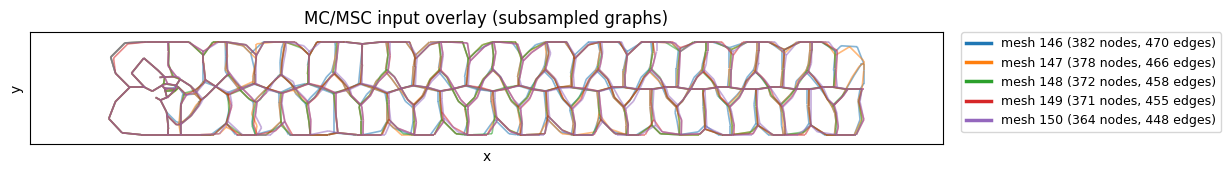

In [7]:
# Overlay all input MSC graphs in one (x, y) view — one edge color per mesh
draw_msc_graphs_overlay(Gs, mesh_ids=mesh_ids)


Same-type feature-cost diagnostics (normalized Euclidean^2 + scalar^2, critical nodes only)
  domain_size=401.998  scalar_range=1.39596
  type_scale = sqrt(P25/2) = 0.145435  (lowest aggregated P25 = 0.0423028 from saddle; type-mismatch cost 2*type_scale^2 = 0.0423028)
input        type        n_nodes  n_pairs        P10        P25        P50        min        max
mesh 146     minimum          29      406   0.004863    0.03033     0.1227   0.001054       1.18
mesh 146     saddle           58     1653    0.01661     0.0429     0.1206  0.0004905      1.366
mesh 146     maximum          30      435   0.005208    0.03317     0.1197   0.001392     0.9587
mesh 147     minimum          29      406   0.004878    0.02953     0.1215   0.001053      1.177
mesh 147     saddle           58     1653    0.01652    0.04293     0.1196  0.0003769      1.351
mesh 147     maximum          30      435   0.005179    0.03319     0.1194   0.001566     0.9567
mesh 148     minimum          29      406   0.00486

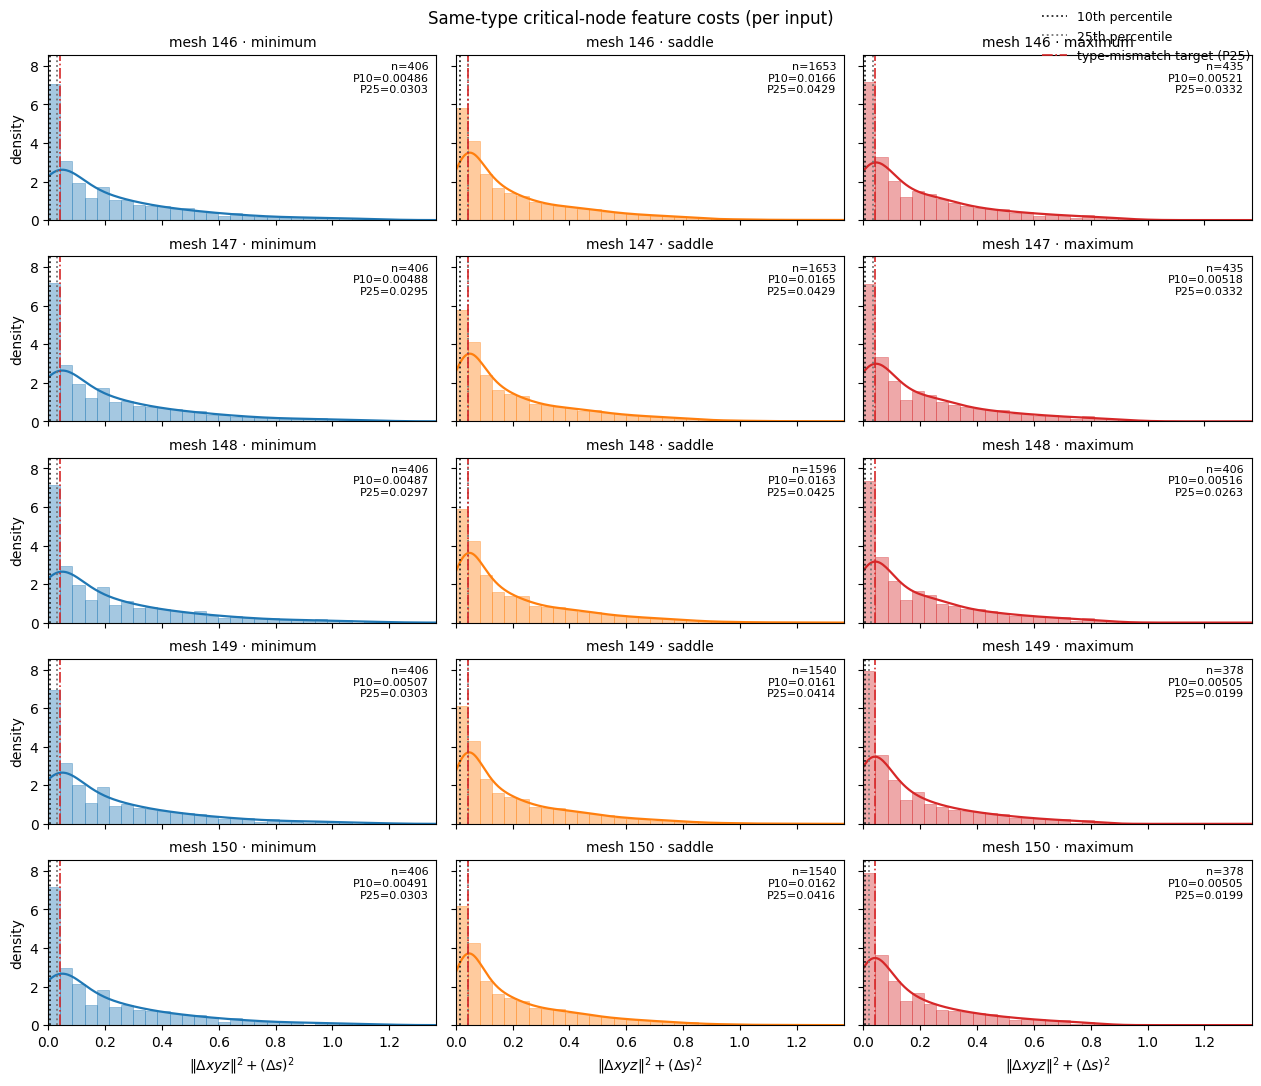

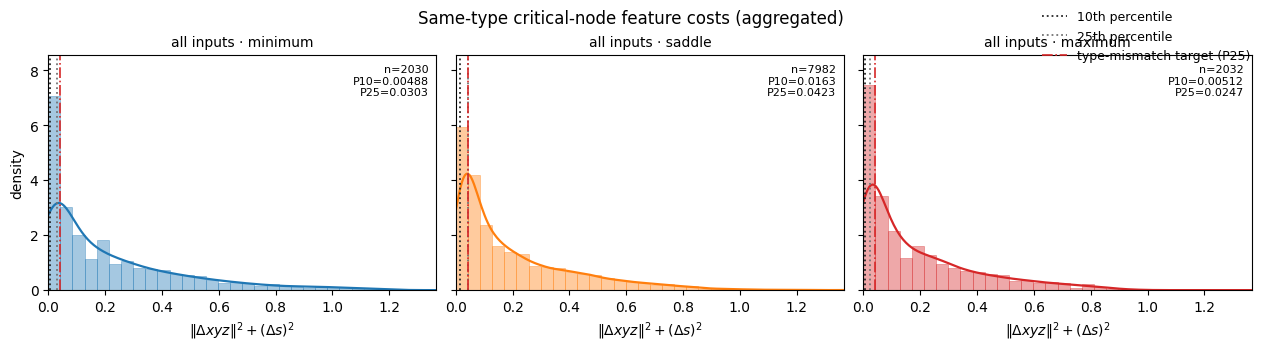

In [8]:
# Same-type pairwise feature costs among critical nodes (after subsampling).
# Cost matches the FGW feature term without the type one-hot:
#   ||xyz_norm_i - xyz_norm_j||^2 + (scalar_norm_i - scalar_norm_j)^2
# Normalization is the same as later FGW features (global domain / scalar range).
# Cross-type extra cost is 2 * type_scale**2. We set
#   type_scale = sqrt(p / 2)
# so that extra cost equals p, the lowest aggregated x-percentile of these
# same-type costs (types with too few pairs are ignored).

CRITICAL_TYPES = (0, 1, 2)
CRITICAL_TYPE_NAMES = {0: "minimum", 1: "saddle", 2: "maximum"}
CRITICAL_TYPE_COLORS = {0: "C0", 1: "C1", 2: "C3"}
SAME_TYPE_PCTS = (10, 25)
TYPE_SCALE_PERCENTILE = 25  # x in "lowest aggregated x-percentile"
TYPE_SCALE_MIN_PAIRS = 10
TYPE_SCALE_FALLBACK = 1.0 / np.sqrt(2)
N_COST_BINS = 32

all_x, all_y, all_z, all_scalars = [], [], [], []
for G in Gs:
    for n in G.nodes():
        all_x.append(G.nodes[n]["x"])
        all_y.append(G.nodes[n]["y"])
        all_z.append(G.nodes[n]["z"])
        all_scalars.append(node_height(G, n))

min_x, max_x = min(all_x), max(all_x)
min_y, max_y = min(all_y), max(all_y)
min_z, max_z = min(all_z), max(all_z)
domain_size = float(np.sqrt((max_x - min_x) ** 2 + (max_y - min_y) ** 2 + (max_z - min_z) ** 2))
domain_size = domain_size if domain_size > 0 else 1.0
min_scalar, max_scalar = min(all_scalars), max(all_scalars)
scalar_range = float(max_scalar - min_scalar)
scalar_range = scalar_range if scalar_range > 0 else 1.0


def _critical_nodes_of_type(G, crit_type):
    return [
        n
        for n in G.nodes()
        if msc_node_visual_type(G.nodes[n]) == crit_type
    ]


def _normalized_xyz_scalar(G, nodes_idx):
    coords = np.array(
        [
            [
                (G.nodes[n]["x"] - min_x) / domain_size,
                (G.nodes[n]["y"] - min_y) / domain_size,
                (G.nodes[n]["z"] - min_z) / domain_size,
            ]
            for n in nodes_idx
        ],
        dtype=float,
    )
    scalars = np.array(
        [(node_height(G, n) - min_scalar) / scalar_range for n in nodes_idx],
        dtype=float,
    )
    return coords, scalars


def same_type_pairwise_feature_costs(G, crit_type):
    nodes_idx = _critical_nodes_of_type(G, crit_type)
    n_nodes = len(nodes_idx)
    if n_nodes < 2:
        return np.array([], dtype=float), n_nodes
    coords, scalars = _normalized_xyz_scalar(G, nodes_idx)
    d2 = np.sum((coords[:, None, :] - coords[None, :, :]) ** 2, axis=-1)
    s2 = (scalars[:, None] - scalars[None, :]) ** 2
    vals = (d2 + s2)[np.triu_indices(n_nodes, k=1)]
    return np.asarray(vals, dtype=float), n_nodes


try:
    from scipy.stats import gaussian_kde
except ImportError:
    gaussian_kde = None


def _kde_curve(vals, x_grid):
    if (
        gaussian_kde is None
        or vals.size < 3
        or float(np.std(vals)) <= 1e-12
    ):
        return None
    return gaussian_kde(vals)(x_grid)


def _density_peak(vals, bin_edges):
    if vals.size == 0:
        return 0.0
    hist, _ = np.histogram(vals, bins=bin_edges, density=True)
    return float(np.max(hist)) if hist.size else 0.0


def _draw_cost_hist(ax, vals, *, color, title, bin_edges, x_grid, x_max, y_max, target_cost=None):
    if vals.size:
        ax.hist(
            vals,
            bins=bin_edges,
            density=True,
            color=color,
            alpha=0.40,
            edgecolor=color,
            linewidth=0.6,
        )
        kde_y = _kde_curve(vals, x_grid)
        if kde_y is not None:
            ax.plot(x_grid, kde_y, color=color, lw=1.6)
        p10, p25 = np.percentile(vals, list(SAME_TYPE_PCTS))
        ax.axvline(p10, color="0.15", ls=":", lw=1.3)
        ax.axvline(p25, color="0.45", ls=":", lw=1.3)
        if target_cost is not None and np.isfinite(target_cost):
            ax.axvline(target_cost, color="C3", ls="-.", lw=1.2)
        ax.text(
            0.98,
            0.96,
            f"n={vals.size}\nP10={p10:.3g}\nP25={p25:.3g}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8,
        )
    else:
        ax.text(
            0.5,
            0.5,
            "n < 2 pairs",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=9,
            color="0.45",
        )
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0.0, x_max)
    ax.set_ylim(0.0, y_max)
    ax.grid(False)


n_inputs = len(Gs)
per_input_costs = {}
agg_costs = {t: [] for t in CRITICAL_TYPES}
summary_rows = []

for i, G in enumerate(Gs):
    mid = mesh_ids[i] if i < len(mesh_ids) else i
    for t in CRITICAL_TYPES:
        vals, n_nodes = same_type_pairwise_feature_costs(G, t)
        per_input_costs[(i, t)] = vals
        if vals.size:
            agg_costs[t].append(vals)
            p10, p25, p50 = np.percentile(vals, [10, 25, 50])
            summary_rows.append(
                (f"mesh {mid}", CRITICAL_TYPE_NAMES[t], n_nodes, vals.size,
                 p10, p25, p50, float(vals.min()), float(vals.max()))
            )
        else:
            summary_rows.append(
                (f"mesh {mid}", CRITICAL_TYPE_NAMES[t], n_nodes, 0,
                 np.nan, np.nan, np.nan, np.nan, np.nan)
            )

for t in CRITICAL_TYPES:
    agg_costs[t] = (
        np.concatenate(agg_costs[t]) if agg_costs[t] else np.array([], dtype=float)
    )
    vals = agg_costs[t]
    if vals.size:
        p10, p25, p50 = np.percentile(vals, [10, 25, 50])
        summary_rows.append(
            ("all inputs", CRITICAL_TYPE_NAMES[t], -1, vals.size,
             p10, p25, p50, float(vals.min()), float(vals.max()))
        )
    else:
        summary_rows.append(
            ("all inputs", CRITICAL_TYPE_NAMES[t], -1, 0,
             np.nan, np.nan, np.nan, np.nan, np.nan)
        )

agg_percentiles = {}
for t in CRITICAL_TYPES:
    vals = agg_costs[t]
    if vals.size >= TYPE_SCALE_MIN_PAIRS:
        agg_percentiles[t] = float(np.percentile(vals, TYPE_SCALE_PERCENTILE))

if agg_percentiles:
    type_scale_src_type = max(agg_percentiles, key=agg_percentiles.get)
    type_scale_percentile_value = agg_percentiles[type_scale_src_type]
    type_scale = float(np.sqrt(type_scale_percentile_value / 2.0))
    type_scale_from_fallback = False
else:
    type_scale_src_type = None
    type_scale_percentile_value = float("nan")
    type_scale = float(TYPE_SCALE_FALLBACK)
    type_scale_from_fallback = True

all_vals = [v for v in per_input_costs.values() if v.size]
all_vals.extend(v for v in agg_costs.values() if v.size)
x_max = max((float(np.max(v)) for v in all_vals), default=1.0)
x_max = x_max if x_max > 0 else 1.0
bin_edges = np.linspace(0.0, x_max, N_COST_BINS + 1)
x_grid = np.linspace(0.0, x_max, 256)
y_max = max(
    (_density_peak(v, bin_edges) for v in all_vals),
    default=1.0,
)
y_max = (1.08 * y_max) if y_max > 0 else 1.0

print(
    "Same-type feature-cost diagnostics "
    "(normalized Euclidean^2 + scalar^2, critical nodes only)"
)
print(
    f"  domain_size={domain_size:.6g}  scalar_range={scalar_range:.6g}"
)
if type_scale_from_fallback:
    print(
        f"  type_scale fallback {type_scale:.6g} "
        f"(no type with >= {TYPE_SCALE_MIN_PAIRS} aggregated pairs); "
        f"type-mismatch cost 2*type_scale^2 = {2.0 * type_scale ** 2:.6g}"
    )
else:
    src_name = CRITICAL_TYPE_NAMES[type_scale_src_type]
    print(
        f"  type_scale = sqrt(P{TYPE_SCALE_PERCENTILE}/2) = {type_scale:.6g}  "
        f"(lowest aggregated P{TYPE_SCALE_PERCENTILE} = {type_scale_percentile_value:.6g} "
        f"from {src_name}; type-mismatch cost 2*type_scale^2 = "
        f"{2.0 * type_scale ** 2:.6g})"
    )
print(
    f"{'input':<12} {'type':<10} {'n_nodes':>8} {'n_pairs':>8} "
    f"{'P10':>10} {'P25':>10} {'P50':>10} {'min':>10} {'max':>10}"
)
finite_p10 = []
finite_p25 = []
for row in summary_rows:
    label, name, n_nodes, n_pairs, p10, p25, p50, vmin, vmax = row
    n_nodes_s = "agg" if n_nodes < 0 else str(n_nodes)
    def _fmt(x):
        return f"{x:10.4g}" if np.isfinite(x) else f"{'n/a':>10}"
    print(
        f"{label:<12} {name:<10} {n_nodes_s:>8} {n_pairs:8d} "
        f"{_fmt(p10)} {_fmt(p25)} {_fmt(p50)} {_fmt(vmin)} {_fmt(vmax)}"
    )
    if label != "all inputs" and np.isfinite(p10):
        finite_p10.append(p10)
        finite_p25.append(p25)

if finite_p10:
    print(
        f"  lowest per-(input, type) P10 = {min(finite_p10):.6g}, "
        f"P25 = {min(finite_p25):.6g}  "
        f"(type_scale uses aggregated P{TYPE_SCALE_PERCENTILE}, not these)"
    )
if agg_percentiles:
    for t, pval in agg_percentiles.items():
        mark = "  <-- used" if t == type_scale_src_type else ""
        print(
            f"  aggregated {CRITICAL_TYPE_NAMES[t]} "
            f"P{TYPE_SCALE_PERCENTILE} = {pval:.6g}{mark}"
        )

fig, axes = plt.subplots(
    n_inputs,
    3,
    figsize=(12.5, max(2.6, 2.15 * n_inputs)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)
for i in range(n_inputs):
    mid = mesh_ids[i] if i < len(mesh_ids) else i
    for j, t in enumerate(CRITICAL_TYPES):
        ax = axes[i, j]
        _draw_cost_hist(
            ax,
            per_input_costs[(i, t)],
            color=CRITICAL_TYPE_COLORS[t],
            title=f"mesh {mid} · {CRITICAL_TYPE_NAMES[t]}",
            bin_edges=bin_edges,
            x_grid=x_grid,
            x_max=x_max,
            y_max=y_max,
            target_cost=type_scale_percentile_value,
        )
        if i == n_inputs - 1:
            ax.set_xlabel(r"$\|\Delta xyz\|^2 + (\Delta s)^2$")
        if j == 0:
            ax.set_ylabel("density")

from matplotlib.lines import Line2D

_pct_handles = [
    Line2D([0], [0], color="0.15", ls=":", lw=1.3, label="10th percentile"),
    Line2D([0], [0], color="0.45", ls=":", lw=1.3, label="25th percentile"),
]
if not type_scale_from_fallback:
    _pct_handles.append(
        Line2D(
            [0],
            [0],
            color="C3",
            ls="-.",
            lw=1.2,
            label=f"type-mismatch target (P{TYPE_SCALE_PERCENTILE})",
        )
    )
fig.legend(handles=_pct_handles, loc="upper right", frameon=False, fontsize=9)
fig.suptitle("Same-type critical-node feature costs (per input)", fontsize=12)
plt.show()

fig_agg, axes_agg = plt.subplots(
    1,
    3,
    figsize=(12.5, 3.4),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)
for j, t in enumerate(CRITICAL_TYPES):
    ax = axes_agg[0, j]
    _draw_cost_hist(
        ax,
        agg_costs[t],
        color=CRITICAL_TYPE_COLORS[t],
        title=f"all inputs · {CRITICAL_TYPE_NAMES[t]}",
        bin_edges=bin_edges,
        x_grid=x_grid,
        x_max=x_max,
        y_max=y_max,
        target_cost=type_scale_percentile_value,
    )
    ax.set_xlabel(r"$\|\Delta xyz\|^2 + (\Delta s)^2$")
    if j == 0:
        ax.set_ylabel("density")
fig_agg.legend(handles=_pct_handles, loc="upper right", frameon=False, fontsize=9)
fig_agg.suptitle("Same-type critical-node feature costs (aggregated)", fontsize=12)
plt.show()


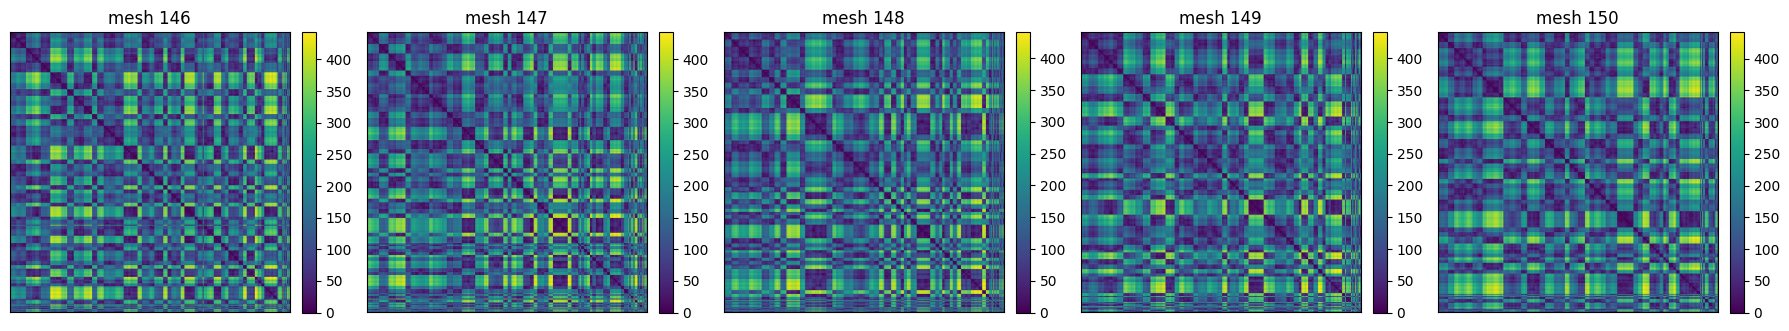

In [9]:
# Relation matrices (lib/graph_reader.relation_matrix — reload after edits)
import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import relation_matrix


def show_relation_matrices(graphs, kind="adjacency", cmap="viridis", sp_weighted=True):
    n = len(graphs)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.2), squeeze=False)
    for i, G in enumerate(graphs):
        C, _ = relation_matrix(G, kind=kind, sp_weighted=sp_weighted)
        ax = axes[0, i]
        im = ax.imshow(C, cmap=cmap)
        ax.set_title(f"mesh {mesh_ids[i]}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


show_relation_matrices(Gs, kind="shortestpath", sp_weighted=True)


In [10]:
### This only works for the synthetic data example.
### We select index=0 as the ground-truth of barycenter (which is a synthetic dataset without any added noises),
### and use it as the initialization for barycenters of other instances.
### In this case, we remove Gs[0] from the list of input.
### If seed_graph_id is None, the next cell picks the input with the minimum
### sum of PFGW distances to all other inputs.
if "synthetic" in str(MSC_DIR):
    seed_graph_id = 0
    exclude_seed = True
else:
    seed_graph_id = None
    exclude_seed = False

In [11]:
# Measure-network initialization and seed selection
# Shortest-path structure uses summed 3D Euclidean edge lengths (sp_weighted=True).
# Rescale: C_scaled = C_raw / max_global_shortest_path (same as contour-tree FGW).
# If seed_graph_id is None, pick the input with minimum sum of PFGW distances
# to all other inputs (same PFGW hyperparameters as the barycenter).

# Node masses (p_i and p) use the discretized arc-length measure
#   mu(v) = ell(v) / sum_e length(e),  ell(v) = (1/2) sum_{e ni v} length(e)
# so every graph has total mass 1. Subdividing an edge only redistributes mass
# on that edge (sampling-invariant on the rest of the graph).
# This flag controls whether the seed graph is expanded to the size of the largest input graph.
# Expansion reinserts nodes dropped during subsampling; the input graphs themselves
# are left at their subsampled size even when one of them is chosen as the seed.
expand_to_largest = True

relation_kind = "shortestpath"
laplacian_base = "adjacency"
laplacian_normalization = "none"
tau = 1.0
sp_weighted = True  # sum 3D Euclidean edge lengths (MSC edges store Euclidean dist)
sp_affinity = "exp"
sp_sigma = None
relation_rescale = 1.0
relation_offset = 0.0

relation_rescale, relation_offset, rescale_diag = compute_relation_rescale(
    Gs, relation_kind, sp_weighted=sp_weighted
)
print("Rescale diagnostics:", rescale_diag)
print("relation_rescale:", relation_rescale)

use_partial = True
idx_list = list[int](range(len(Gs)))
n_graphs = len(idx_list) if not exclude_seed else len(idx_list) - 1
N_maxnode = max(Gs[idx].number_of_nodes() for idx in idx_list)
lambdas = np.ones(n_graphs, dtype=float) / n_graphs
max_iter = 200
bary_tol = 1e-6
random_state = 0
lambda_penalty = 0.002
# Geometric λ decay: q = (lambda_init / lambda_target) ** (1 / decay_steps)
# λ_0 = lambda_init, λ_{k+1} = max(lambda_target, λ_k / q). Target is lambda_penalty.
lambda_init = 0.1
decay_steps = 2
alpha_fgw = 0.5
gw_restarts = 10
gw_seed_start = 0

print(
    "lambda_penalty:", lambda_penalty,
    "lambda_init:", lambda_init,
    "decay_steps:", decay_steps,
    "alpha_fgw:", alpha_fgw,
)

# Node features for FGW: normalized (x, y, z) + normalized scalar + critical-point type
MSC_TYPE_ORDER = [0, 1, 2, -1]  # minimum, saddle, maximum, regular
type_to_idx = {t: i for i, t in enumerate(MSC_TYPE_ORDER)}
n_types = len(MSC_TYPE_ORDER)
# type_scale is set in the same-type cost diagnostic: sqrt(p/2) so that
# 2 * type_scale**2 equals the lowest aggregated x-percentile of same-type costs.
if "type_scale" not in globals():
    type_scale = 1.0 / np.sqrt(2)
print(
    f"type_scale={float(type_scale):.6g}  "
    f"type-mismatch cost 2*type_scale^2={2.0 * float(type_scale) ** 2:.6g}"
)

all_x, all_y, all_z = [], [], []
all_scalars = []
for idx in idx_list:
    G = Gs[idx]
    for n in G.nodes():
        all_x.append(G.nodes[n]["x"])
        all_y.append(G.nodes[n]["y"])
        all_z.append(G.nodes[n]["z"])
        all_scalars.append(node_height(G, n))

min_x, max_x = min(all_x), max(all_x)
min_y, max_y = min(all_y), max(all_y)
min_z, max_z = min(all_z), max(all_z)
domain_size = np.sqrt((max_x - min_x) ** 2 + (max_y - min_y) ** 2 + (max_z - min_z) ** 2)
domain_size = domain_size if domain_size > 0 else 1.0
min_scalar, max_scalar = min(all_scalars), max(all_scalars)
scalar_range = max_scalar - min_scalar
scalar_range = scalar_range if scalar_range > 0 else 1.0

def msc_fgw_features(G, nodes_idx):
    coords = np.array(
        [
            [
                (G.nodes[n]["x"] - min_x) / domain_size,
                (G.nodes[n]["y"] - min_y) / domain_size,
                (G.nodes[n]["z"] - min_z) / domain_size,
            ]
            for n in nodes_idx
        ],
        dtype=float,
    )
    scalars = np.array(
        [(node_height(G, n) - min_scalar) / scalar_range for n in nodes_idx],
        dtype=float,
    ).reshape(-1, 1)
    onehot = np.zeros((len(nodes_idx), n_types), dtype=float)
    for i, n in enumerate(nodes_idx):
        onehot[i, type_to_idx[msc_node_visual_type(G.nodes[n])]] = type_scale
    return np.column_stack([coords, scalars, onehot])


def msc_scaled_relation(G):
    C_idx, nodes_idx = relation_matrix(
        G,
        kind=relation_kind,
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=tau,
        sp_weighted=sp_weighted,
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
    )
    if relation_kind == "shortestpath":
        C_idx = apply_relation_scaling(
            C_idx, relation_kind, relation_rescale, relation_offset
        )
    return C_idx, nodes_idx


Ys = []
Cs = []
nodes_list = []
ps = []
for idx in idx_list:
    G = Gs[idx]
    C_idx, nodes_idx = msc_scaled_relation(G)
    Cs.append(C_idx)
    nodes_list.append(nodes_idx)
    Ys.append(msc_fgw_features(G, nodes_idx))
    ps.append(arc_length_node_measure(G, nodelist=nodes_idx, rescale_factor=1.0))

for i, pe in enumerate(ps):
    print(
        f"  input {i} mesh {mesh_ids[i]}: n={len(pe)}, "
        f"arc-length mass sum={float(pe.sum()):.6f}, "
        f"min={float(pe.min()):.4g}, max={float(pe.max()):.4g}"
    )

# Seed: specified index, or the input with minimum sum of PFGW distances
# to all other measure networks (ties keep the earliest index).
if seed_graph_id is None:
    print("No seed specified; selecting the input with minimum PFGW sum to all others.")
    pair_lambda = 1000.0 if not use_partial else float(lambda_penalty)
    seed_graph_id, pfgw_pair_D, pfgw_pair_sums = select_seed_by_min_pfgw_sum(
        Cs,
        Ys,
        ps,
        lambda_penalty=pair_lambda,
        alpha_fgw=alpha_fgw,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        max_iter=max_iter,
        verbose=True,
    )
    print("PFGW pairwise costs (symmetric):")
    print(pfgw_pair_D)
    for i, s in enumerate(pfgw_pair_sums):
        mark = " <-- selected" if i == seed_graph_id else ""
        print(f"  idx {i} mesh {mesh_ids[i]}: sum={float(s):.6g}{mark}")
else:
    print(
        f"Using specified seed_graph_id={seed_graph_id} "
        f"(mesh {mesh_ids[seed_graph_id]})"
    )

N_center = Gs[seed_graph_id].number_of_nodes()
p = ps[seed_graph_id].copy()

# We put the index exclusion for seed network here.
# Because all previous computations involve all instances (initialization, measure network setups).
if exclude_seed:
    Cs_input = Cs[:seed_graph_id]
    Cs_input.extend(Cs[seed_graph_id + 1:])
    ps_input = ps[:seed_graph_id]
    ps_input.extend(ps[seed_graph_id + 1:])
    Ys_input = Ys[:seed_graph_id]
    Ys_input.extend(Ys[seed_graph_id + 1:])
    idx_list.remove(seed_graph_id)
else:
    Cs_input = Cs
    ps_input = ps
    Ys_input = Ys
    
init_C = Cs[seed_graph_id]
init_X = Ys[seed_graph_id]
init_p = p
if expand_to_largest and N_center < N_maxnode:
    seed_n_before = Gs[seed_graph_id].number_of_nodes()
    G_seed_expanded, expand_info = expand_sampled_graph_to_size(
        Gs[seed_graph_id],
        N_maxnode,
        source_graph=raw_graphs[seed_graph_id],
    )
    assert Gs[seed_graph_id].number_of_nodes() == seed_n_before, (
        "Seed expansion must not change the subsampled input graph size."
    )
    inserted = expand_info["inserted_nodes"]
    print(
        "Reinserted dropped seed nodes: "
        f"{expand_info['n_inserted']} "
        f"({expand_info['n_start']} -> {expand_info['n_end']}, "
        f"target {expand_info['n_target']}, "
        f"skipped_edges={expand_info['n_skipped_edges']})"
    )
    if inserted:
        ins_types = np.array(
            [
                msc_node_visual_type(raw_graphs[seed_graph_id].nodes[n])
                for n in inserted
            ],
            dtype=int,
        )
        print(
            "Inserted node types: "
            f"minima={int(np.sum(ins_types == 0))}, "
            f"saddles={int(np.sum(ins_types == 1))}, "
            f"maxima={int(np.sum(ins_types == 2))}, "
            f"regular={int(np.sum(ins_types == -1))}"
        )
    init_C, init_nodes = msc_scaled_relation(G_seed_expanded)
    init_X = msc_fgw_features(G_seed_expanded, init_nodes)
    init_p = arc_length_node_measure(G_seed_expanded, nodelist=init_nodes, rescale_factor=1.0)
    N_center = int(init_C.shape[0])
    p = init_p

print(
    f"Seed network: idx={seed_graph_id}, mesh={mesh_ids[seed_graph_id]}, "
    f"n_nodes={Gs[seed_graph_id].number_of_nodes()}, N_center={N_center}, "
    f"exclude_seed={exclude_seed}, expand_to_largest={expand_to_largest}"
)


Rescale diagnostics: {'relation_kind': 'shortestpath', 'sp_weighted': True, 'max_dist_per_graph': [443.8268203325524, 443.7297845533533, 441.85065034347394, 442.2610190167557, 442.6408935832524], 'max_dist_global': 443.8268203325524}
relation_rescale: 0.0022531310731756043
lambda_penalty: 0.002 lambda_init: 0.1 decay_steps: 2 alpha_fgw: 0.5
type_scale=0.145435  type-mismatch cost 2*type_scale^2=0.0423028
  input 0 mesh 146: n=382, arc-length mass sum=1.000000, min=8.179e-05, max=0.005296
  input 1 mesh 147: n=378, arc-length mass sum=1.000000, min=0.0004066, max=0.005204
  input 2 mesh 148: n=372, arc-length mass sum=1.000000, min=8.336e-05, max=0.005271
  input 3 mesh 149: n=371, arc-length mass sum=1.000000, min=0.0001425, max=0.005162
  input 4 mesh 150: n=364, arc-length mass sum=1.000000, min=8.353e-05, max=0.005282
No seed specified; selecting the input with minimum PFGW sum to all others.
Computing 10 unique PFGW pairs over 5 networks (symmetric, gw_restarts=10)...
  pair (0, 1)

In [12]:
# Barycenter computation: geometric λ-decay PFGW (lambda_converge)
# Each λ is solved to convergence; (C, X, T) warm-start the next (smaller) λ.
# Progress: tqdm over the λ schedule, plus per-step FPGW loss sum and transported masses.
# PFGW cost helper lives in lib.msc_barycenter_eval.pfgw_total_cost (shared with evaluation notebook)

def _pfgw_total_cost(C_tmp, X_tmp, p, Cs, Ys, ps, Lambda_list, lambdas, log_tmp, debug=False):
    return pfgw_total_cost(
        C_tmp,
        X_tmp,
        log_tmp["T"],
        Cs=Cs,
        Ys=Ys,
        p=p,
        ps=ps,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha_fgw=alpha_fgw,
        debug=debug,
    )

lambda_target = float(lambda_penalty)
print(
    f"λ-converge schedule: init={lambda_init:g} -> target={lambda_target:g}, "
    f"decay_steps={decay_steps}"
)
print("λ values:", lambda_decay_schedule(lambda_init, lambda_target, decay_steps))

C_center_final, X_center_final, log_final = pfgw_barycenters_lambda_converge(
    N=N_center,
    Ys=Ys_input,
    Cs=Cs_input,
    ps=ps_input,
    p=init_p,
    lambdas=lambdas,
    alpha=alpha_fgw,
    lambda_init=lambda_init,
    lambda_target=lambda_target,
    decay_steps=decay_steps,
    max_iter=max_iter,
    tol=bary_tol,
    init_C=init_C,
    init_X=init_X,
    random_state=random_state,
    gw_restarts=gw_restarts,
    gw_seed_start=gw_seed_start,
    debug=False,
    progress=True,
)

# Working copies for postprocess / save / color transfer (do not mutate _final).
C_center = np.asarray(C_center_final, dtype=float).copy()
X_center = np.asarray(X_center_final, dtype=float).copy()
log = dict(log_final)
log["T"] = [np.asarray(T, dtype=float).copy() for T in log_final["T"]]
if "X" in log_final:
    log["X"] = np.asarray(log_final["X"], dtype=float).copy()
if "p" in log_final:
    log["p"] = np.asarray(log_final["p"], dtype=float).copy()
Lambda_list = [float(lambda_target)] * n_graphs

print("relation_kind:", relation_kind)
print("Barycenter matrix shape:", C_center.shape)
print("Barycenter feature shape:", X_center.shape)
if relation_kind == "shortestpath":
    C_center = np.nan_to_num(C_center, nan=np.inf, posinf=np.inf)
    C_center_final = C_center
elif relation_kind == "adjacency":
    C_center = np.nan_to_num(C_center, nan=0.0)
    C_center_final = C_center

print(
    "Final PFGW Cost (λ_target):",
    _pfgw_total_cost(
        C_center, X_center, init_p, Cs_input, Ys_input, ps_input,
        Lambda_list, lambdas, log, debug=True,
    ),
)
print("λ schedule:", log["lambda_schedule"])
print("step-wise FPGW loss sums:", log["lambda_converge_loss"])
print("step-wise transported masses:", log["lambda_converge_transported_mass"])


λ-converge schedule: init=0.1 -> target=0.002, decay_steps=2
λ values: [0.1, 0.01414213562373095, 0.002]


λ convergence:   0%|          | 0/3 [00:00<?, ?λ/s]

[λ converge 1/3] λ=0.1  FPGW loss sum=0.000439711  transported mass=[1.000000000000001, 1.000000000000001, 1.000000000000001, 1.0000000000000013, 1.0000000000000013]
[λ converge 2/3] λ=0.0141421  FPGW loss sum=0.00043814  transported mass=[1.000000000000001, 1.000000000000001, 0.9996425444015307, 0.9999815803645076, 0.9999850755845723]
[λ converge 3/3] λ=0.002  FPGW loss sum=0.000269858  transported mass=[0.9880604316824602, 0.9985515980676838, 0.9831270510634027, 0.9807074375351308, 0.9817052389159886]
relation_kind: shortestpath
Barycenter matrix shape: (382, 382)
Barycenter feature shape: (382, 8)
d, penalty: 0.00018817219354150174 9.49463333738918e-05
d, penalty: 0.00010127805982010723 1.1578823985908483e-05
d, penalty: 0.00016923036796204373 0.0001338448058695203
d, penalty: 0.00018665486768021535 0.00015285168785311986
d, penalty: 0.00016571237134254172 0.0001450192955396159
Final PFGW Cost (λ_target): 0.0002698577613936933
λ schedule: [0.1, 0.01414213562373095, 0.002]
step-wise 

Barycenter Morse-type diagnostics
  n_nodes=382  eps=1e-06  one-hot X[:, 4:8]  order=[0, 1, 2, -1]
  type_scale=0.145435  (input one-hots are 0 or type_scale; barycenter may be soft)

1) Node counts by argmax type
  type         code  n_nodes     frac
  minimum         0       29    7.59%
  saddle          1       58   15.18%
  maximum         2       30    7.85%
  regular        -1      265   69.37%

2) Ambiguous-type nodes (2+ one-hot entries > eps)
  n_ambiguous=1 / 382
       i argmax      one-hot    minimum      saddle     maximum     regular
     220 maximum                      0           0     0.07734      0.0681

3) Cross-type couplings (T_ij > eps and argmax types differ)
  label                     T>eps     same    cross    same_mass   cross_mass  n_bary_cross
  input 0 mesh 146            699      699        0       0.9881            0             0
  input 1 mesh 147            386      386        0       0.9986            0             0
  input 2 mesh 148            64

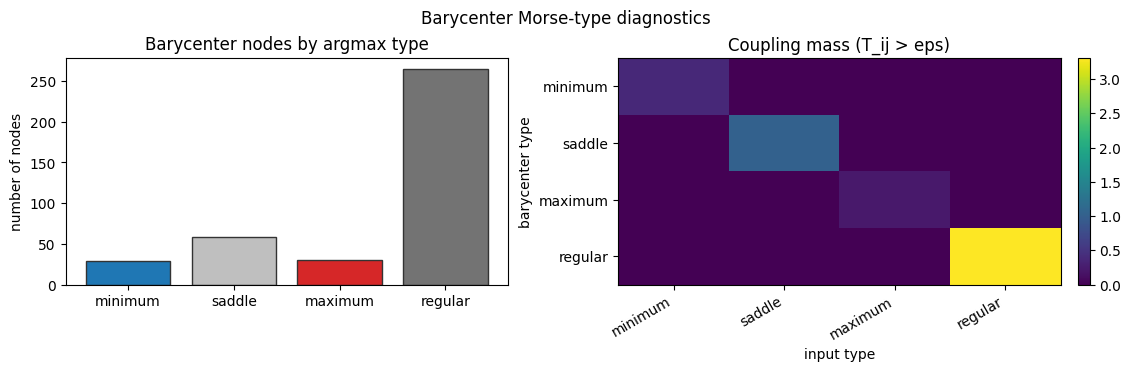

In [13]:
# Diagnostic: barycenter Morse types, ambiguous one-hots, and cross-type couplings.
# Uses the raw PFGW output (before coupling-support prune).
# Feature layout: [x, y, z, scalar] + one-hot over MSC_TYPE_ORDER (scaled by type_scale).

TYPE_DIAG_EPS = 1e-6
_type_diag_labels = [
    f"input {s} mesh {mesh_ids[idx]}"
    for s, idx in enumerate(idx_list)
]
_bary_type_diag = diagnose_barycenter_morse_types(
    X_center,
    Ys_input,
    log["T"],
    msc_type_order=MSC_TYPE_ORDER,
    type_col_start=4,
    eps=TYPE_DIAG_EPS,
    type_scale=float(type_scale),
    input_labels=_type_diag_labels,
)


In [14]:
# Postprocess: drop barycenter nodes without substantial couplings to every input.
# A node i is kept iff, for every input s:
#   - some T[s][i, j] is at least the color-transfer noise floor p.sum() / (n_bary * n_s)
#   - the transported mass T[s][i].sum() is at least MIN_COUPLING_FRACTION * p[i]
# C_center / X_center / p / log["T"] are restricted to the surviving nodes.

MIN_COUPLING_FRACTION = 0.01

_p_bary = log["p"] if "p" in log else init_p
C_center, X_center, _p_bary, Ts_pruned, keep_idx, _prune_info = (
    prune_barycenter_nodes_lacking_all_input_support(
        C_center,
        X_center,
        _p_bary,
        log["T"],
        min_matched_fraction=MIN_COUPLING_FRACTION,
    )
)
log["T"] = Ts_pruned
log["p"] = _p_bary
if "X" in log:
    log["X"] = X_center
init_p = _p_bary
p = _p_bary
N_center = int(keep_idx.size)

print(
    f"Coupling-support prune: kept { _prune_info['n_after'] } / "
    f"{ _prune_info['n_before'] } nodes "
    f"(dropped { _prune_info['n_dropped'] }); "
    f"remaining mass = { _prune_info['remaining_mass']:.6g} "
    f"(min_matched_fraction={MIN_COUPLING_FRACTION})"
)
for s, n_bad in enumerate(_prune_info["n_unsupported_per_input"]):
    print(f"  input {s}: {n_bad} nodes below support threshold")
print("Barycenter matrix shape:", C_center.shape)
print("Barycenter feature shape:", X_center.shape)
print(
    "PFGW Cost (after prune):",
    _pfgw_total_cost(
        C_center, X_center, init_p, Cs_input, Ys_input, ps_input,
        Lambda_list, lambdas, log, debug=True,
    ),
)


Coupling-support prune: kept 379 / 382 nodes (dropped 3); remaining mass = 0.996984 (min_matched_fraction=0.01)
  input 0: 0 nodes below support threshold
  input 1: 0 nodes below support threshold
  input 2: 2 nodes below support threshold
  input 3: 2 nodes below support threshold
  input 4: 2 nodes below support threshold
Barycenter matrix shape: (379, 379)
Barycenter feature shape: (379, 8)
d, penalty: 0.00018699876502207625 0.00010346338446713377
d, penalty: 9.972576747678107e-05 2.358958501457886e-05
d, penalty: 0.0001689107252708463 0.00012625517314568668
d, penalty: 0.0001863377657386062 0.00014525108494180117
d, penalty: 0.0001639935280545619 0.00013629988806579575
PFGW Cost (after prune): 0.0002681651334395736


In [15]:
print(log['T'][1])

[[0.0043156  0.         0.         ... 0.         0.         0.        ]
 [0.         0.00206743 0.         ... 0.         0.         0.        ]
 [0.         0.         0.00280263 ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


Barycenter MST: 379 nodes, 378 edges
Complete barycenter graph: 379 nodes, 71631 edges (71631 candidates)
unscaled weight - euclidean (MST edges): [ 4.26323436e-02  2.08049805e+00  1.07703252e+00  2.46019509e-01
  4.56577264e-01  1.66950611e-01  7.12996988e-01  8.62096402e-01
  1.01122872e-01  8.96733614e+00  4.76632565e+00  3.07049405e-01
  4.76624584e-01  3.45134253e+00  4.54276700e+00  1.41215325e-01
  6.73826321e-01  1.17110982e+00  1.27672954e+00  1.82001459e-01
  1.92016216e-01  3.12311750e-01  1.84353210e-02  3.23690370e-01
  1.13303124e-01  1.34124051e+00  6.37804989e-01  3.85319627e-01
  6.28895151e-01  2.33932163e-01  2.79655897e+00  3.50194192e+00
  2.54761559e-02  5.16727646e-03  1.91879857e+00  4.06542733e-01
  2.02608371e-01  7.70845707e-01  4.04219250e-01  2.80735502e-01
  3.91190512e+00  5.85485460e-01  1.53792820e-01  1.31627996e+00
  2.73321674e-01  9.12036417e-01  1.70176837e+00  1.95974907e+00
  1.06568032e+00  6.47879644e-01  2.10370880e-01  4.47165667e+00
  5.4785

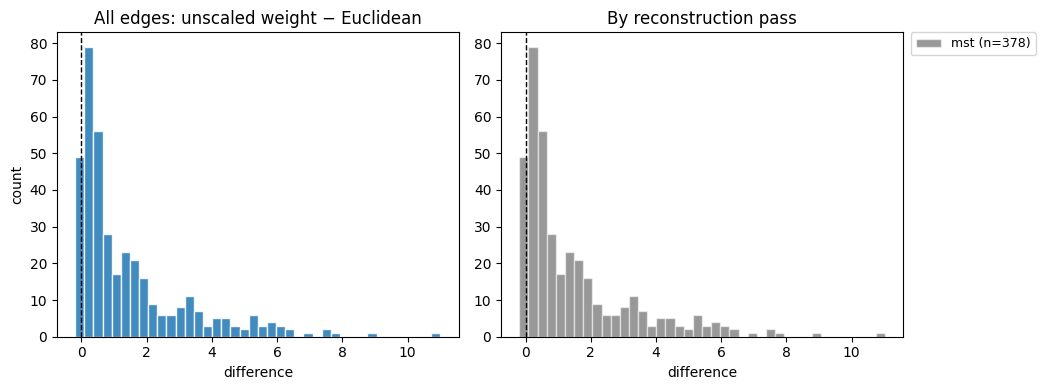

relation unscale: kind=shortestpath, sp_weighted=True, rescale=0.00225313, offset=0
unscaled weight − euclidean: n=378, min=-0.190692, max=11.011, mean=1.45693, std=1.76148, below_eucl=1
Top |difference| edges:
  (271, 360) pass=mst weight_scaled=0.0299211 weight_raw=13.2798 eucl=2.26876 diff=11.011
  (6, 202) pass=mst weight_scaled=0.0207733 weight_raw=9.21976 eucl=0.252428 diff=8.96734
  (65, 66) pass=mst weight_scaled=0.0252241 weight_raw=11.1951 eucl=3.34619 diff=7.84892
  (129, 280) pass=mst weight_scaled=0.0253452 weight_raw=11.2489 eucl=3.68855 diff=7.56034
  (213, 214) pass=mst weight_scaled=0.0202542 weight_raw=8.98936 eucl=1.42976 diff=7.5596


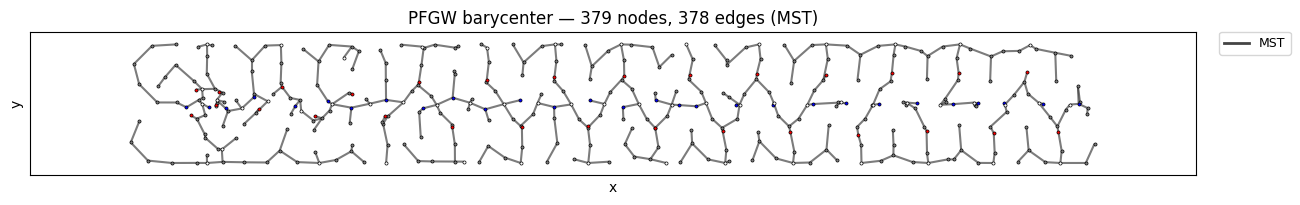

Saved barycenter bundle -> C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\VortexStreet_lambda_converge_09-01-2026-17-24-44 (saved_at=09-01-2026-17-24-44, exclude_seed=False, seed_graph_id=1, n_inputs=5)


In [16]:
# Reconstruct MST barycenter, build complete (pre-threshold) graph, and save bundle
importlib.reload(barycenter_io)
from lib.barycenter_io import (
    save_barycenter_bundle,
    timestamped_barycenter_outdir,
    barycenter_save_timestamp,
    build_barycenter_run_meta,
)

G_center = reconstruct_msc_barycenter_mst_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    scalar_min=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
)

print(
    f"Barycenter MST: {G_center.number_of_nodes()} nodes, {G_center.number_of_edges()} edges"
)

# Complete (unthresholded) barycenter graph: all finite positive C_center edges
G_complete, complete_candidates = build_complete_barycenter_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    scalar_min=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
)
print(
    f"Complete barycenter graph: {G_complete.number_of_nodes()} nodes, "
    f"{G_complete.number_of_edges()} edges "
    f"({len(complete_candidates)} candidates)"
)

weight_eucl_diffs = msc_barycenter_weight_euclidean_differences(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
)
print("unscaled weight - euclidean (MST edges):", weight_eucl_diffs)
plot_msc_barycenter_weight_euclidean_debug(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
    bins=40,
    by_pass=True,
)
draw_msc_barycenter_graph(G_center)

# --- persist fully loadable bundle for evaluation notebook ---
# Cs_input / Ys_input / ps_input are the PFGW barycenter inputs (seed omitted when
# exclude_seed). The seed itself is stored under seed/ so evaluation can score
# an out-of-set baseline without mixing it into the input family.
# Folder name includes mm-dd-yyyy-hh-mm-ss so consecutive runs never overlap.
saved_at = barycenter_save_timestamp()
BARYCENTER_OUTDIR = timestamped_barycenter_outdir(
    f"{DATA_KEYWORD}_lambda_converge", saved_at=saved_at
)
nodes_list_input = (
    nodes_list[:seed_graph_id] + nodes_list[seed_graph_id + 1 :]
    if exclude_seed
    else nodes_list
)
save_kwargs = dict(
    C_center=C_center,
    X_center=X_center,
    p=init_p,
    Cs=Cs_input,
    Ys=Ys_input,
    ps=ps_input,
    Ts=log["T"],
    lambdas=lambdas,
    nodes_list=nodes_list_input,
    Gs=[Gs[i] for i in idx_list],
    G_mst=G_center,
    G_complete=G_complete,
    mesh_ids=[mesh_ids[i] for i in idx_list],
    exclude_seed=bool(exclude_seed),
    seed_graph_id=int(seed_graph_id),
    meta=build_barycenter_run_meta(
        source_notebook="msc_barycenter_lambda_converge.ipynb",
        pipeline="lambda_converge",
        saved_at=saved_at,
        DATA_ROOT=DATA_ROOT,
        DATA_KEYWORD=DATA_KEYWORD,
        MSC_DIR=MSC_DIR,
        configured_mesh_ids=list(mesh_ids),
        SAMPLE_RATE=SAMPLE_RATE,
        SAMPLE_MODE=SAMPLE_MODE,
        SAMPLE_COMPONENT=SAMPLE_COMPONENT,
        seed_graph_id=int(seed_graph_id),
        exclude_seed=bool(exclude_seed),
        expand_to_largest=bool(expand_to_largest),
        relation_kind=relation_kind,
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=float(tau),
        sp_weighted=bool(sp_weighted),
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
        relation_rescale=float(relation_rescale),
        relation_offset=float(relation_offset),
        MSC_TYPE_ORDER=list(MSC_TYPE_ORDER),
        type_scale=float(type_scale),
        TYPE_SCALE_PERCENTILE=int(globals().get("TYPE_SCALE_PERCENTILE", 10)),
        type_scale_percentile_value=(
            None
            if "type_scale_percentile_value" not in globals()
            or not np.isfinite(type_scale_percentile_value)
            else float(type_scale_percentile_value)
        ),
        n_types=int(n_types),
        min_x=min_x,
        max_x=max_x,
        min_y=min_y,
        max_y=max_y,
        min_z=min_z,
        max_z=max_z,
        domain_size=domain_size,
        min_scalar=min_scalar,
        max_scalar=max_scalar,
        scalar_range=scalar_range,
        node_measure="arc_length",
        node_measure_rescale_factor=1.0,
        balanced_distribution=True,
        use_partial=bool(use_partial),
        n_graphs=int(n_graphs),
        N_maxnode=int(N_maxnode),
        N_center=int(N_center),
        alpha_fgw=float(alpha_fgw),
        lambda_penalty=None if lambda_penalty is None else float(lambda_penalty),
        Lambda_list=list(Lambda_list) if Lambda_list is not None else None,
        max_iter=int(max_iter),
        bary_tol=float(bary_tol),
        random_state=int(random_state) if random_state is not None else None,
        gw_restarts=int(gw_restarts),
        gw_seed_start=int(gw_seed_start),
        loss_fun="square_loss",
        stop_criterion="barycenter",
        accumulate_fails_limit=10,
        pfgw_debug=False,
        MIN_COUPLING_FRACTION=float(MIN_COUPLING_FRACTION),
        lambda_init=float(lambda_init),
        lambda_target=float(lambda_target),
        decay_steps=int(decay_steps),
        lambda_schedule=list(log.get("lambda_schedule", [])),
        lambda_converge_loss=list(log.get("lambda_converge_loss", [])),
        lambda_converge_transported_mass=list(
            log.get("lambda_converge_transported_mass", [])
        ),
    ),
    build_complete_if_missing=False,
)
if exclude_seed:
    save_kwargs.update(
        C_seed=Cs[seed_graph_id],
        Y_seed=Ys[seed_graph_id],
        p_seed=ps[seed_graph_id],
        G_seed=Gs[seed_graph_id],
        seed_nodes=nodes_list[seed_graph_id],
        seed_mesh_id=mesh_ids[seed_graph_id],
    )
BARYCENTER_OUTDIR = save_barycenter_bundle(BARYCENTER_OUTDIR, **save_kwargs)
print(
    f"Saved barycenter bundle -> {BARYCENTER_OUTDIR.resolve()} "
    f"(saved_at={saved_at}, exclude_seed={exclude_seed}, "
    f"seed_graph_id={seed_graph_id}, n_inputs={len(Cs_input)})"
)


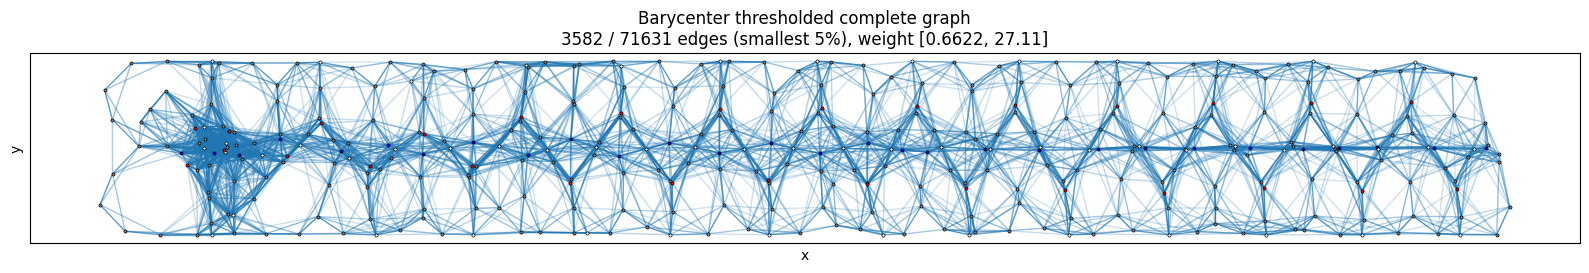

Kept 3582 edges (5% of 71631 candidates); alpha in [0.2, 1.0] by weight


[(0.6621604048391557, 220, 222),
 (1.1031733280167764, 52, 53),
 (1.3363213061744639, 220, 249),
 (1.6337759523643338, 304, 306),
 (1.648182360590277, 250, 308),
 (1.6807356707262942, 254, 255),
 (1.754544523838105, 120, 121),
 (1.762676160380699, 223, 249),
 (1.7934281725690888, 20, 21),
 (1.9397071260094714, 110, 111),
 (1.9559076731566138, 79, 80),
 (2.0112048933195346, 222, 249),
 (2.0460030433638217, 61, 62),
 (2.0553600020681615, 261, 263),
 (2.121320343559643, 224, 263),
 (2.1999044998353825, 220, 223),
 (2.4178545130446736, 256, 257),
 (2.567677896295932, 262, 358),
 (2.7668682984677964, 25, 28),
 (2.772092402421569, 153, 155),
 (2.7873799558744725, 222, 223),
 (2.8643282942289057, 115, 353),
 (2.9412755072533017, 136, 137),
 (2.964760443173749, 253, 260),
 (2.9740896434856112, 130, 138),
 (3.1117491164603845, 169, 170),
 (3.2004379947191994, 323, 324),
 (3.2673829228404916, 243, 321),
 (3.3121146222887297, 258, 259),
 (3.392520156826411, 303, 304),
 (3.427215000250584, 172, 17

In [17]:
# Alternative barycenter view: keep smallest-weight X% of complete-graph edges

EDGE_FRACTION_PCT = 5.0
ALPHA_MIN = 0.2
ALPHA_MAX = 1.0

_pos_recon = {
    n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float)
    for n in G_center.nodes()
}

draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    pos=_pos_recon,
    node_attr_graph=G_center,
)


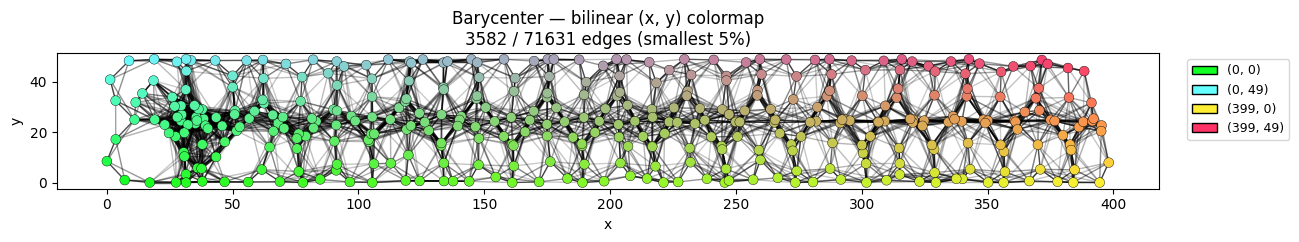

Colormap mode: bilinear; kept 3582 edges (5% of 71631 candidates)


In [18]:
# Color transfer (1): barycenter colormap — bilinear (x, y) or categorical (node id)

BARYCENTER_COLOR_MODE = "bilinear"  # "bilinear" | "categorical"
BARYCENTER_CORNER_COLORS = DEFAULT_CORNER_COLORS
BARYCENTER_CATEGORICAL_CMAP = "tab20"
BARYCENTER_CATEGORICAL_MAX_COLORS = 20

_pos_barycenter = {
    n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float)
    for n in G_center.nodes()
}

barycenter_node_colors = compute_barycenter_node_colors(
    BARYCENTER_COLOR_MODE,
    X_center.shape[0],
    _pos_barycenter,
    min_x=min_x,
    max_x=max_x,
    min_y=min_y,
    max_y=max_y,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
)

barycenter_node_colors = draw_barycenter_colormap(
    C_center,
    X_center,
    barycenter_node_colors,
    color_mode=BARYCENTER_COLOR_MODE,
    min_x=min_x,
    min_y=min_y,
    max_x=max_x,
    max_y=max_y,
    min_z=min_z,
    domain_size=domain_size,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    node_size=50,
    pos=_pos_barycenter,
)

barycenter_bilinear_colors = barycenter_node_colors  # alias


Graph 0: coupling threshold = 6.8863e-06; pie nodes = 224 / 382
Graph 1: coupling threshold = 6.95917e-06; pie nodes = 8 / 378
Graph 2: coupling threshold = 7.07141e-06; pie nodes = 237 / 372
Graph 3: coupling threshold = 7.09047e-06; pie nodes = 239 / 371
Graph 4: coupling threshold = 7.22683e-06; pie nodes = 231 / 364


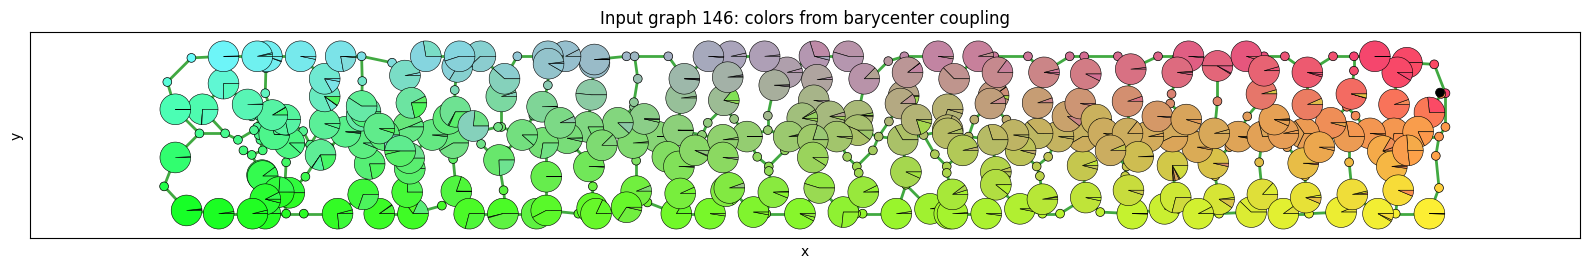

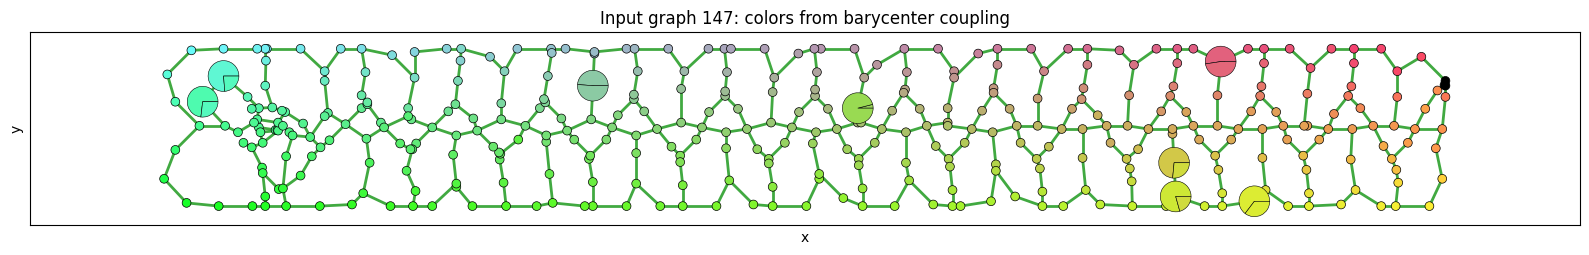

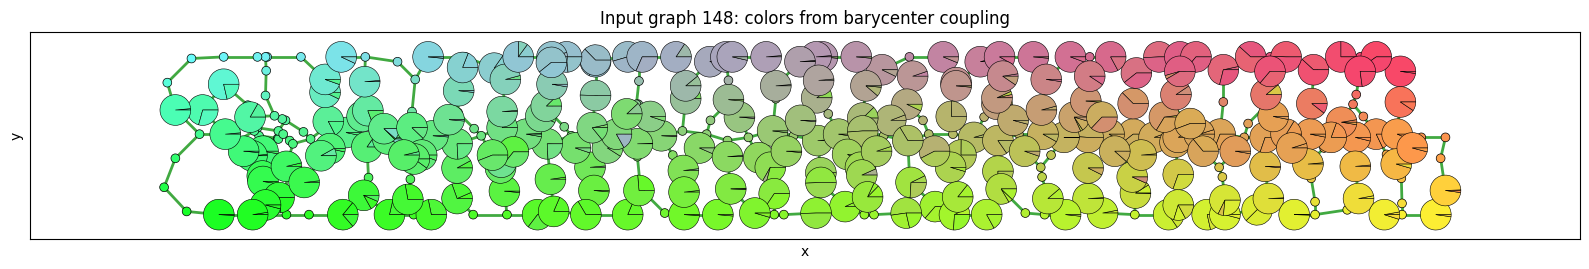

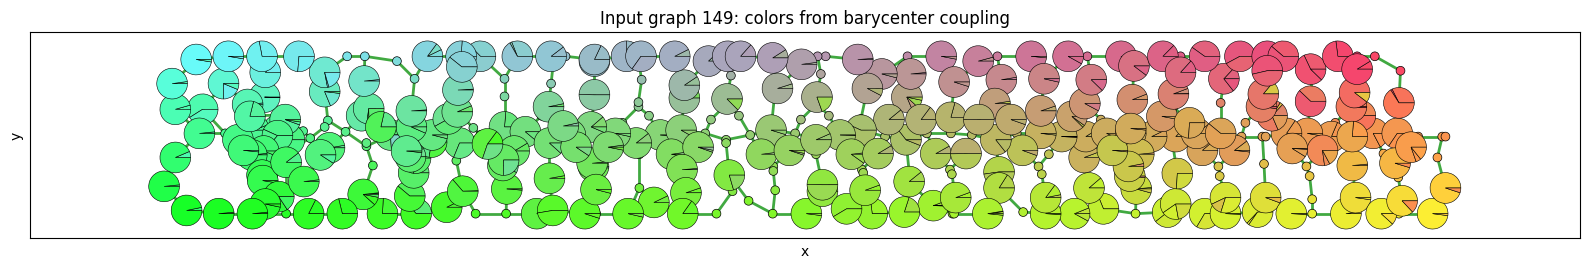

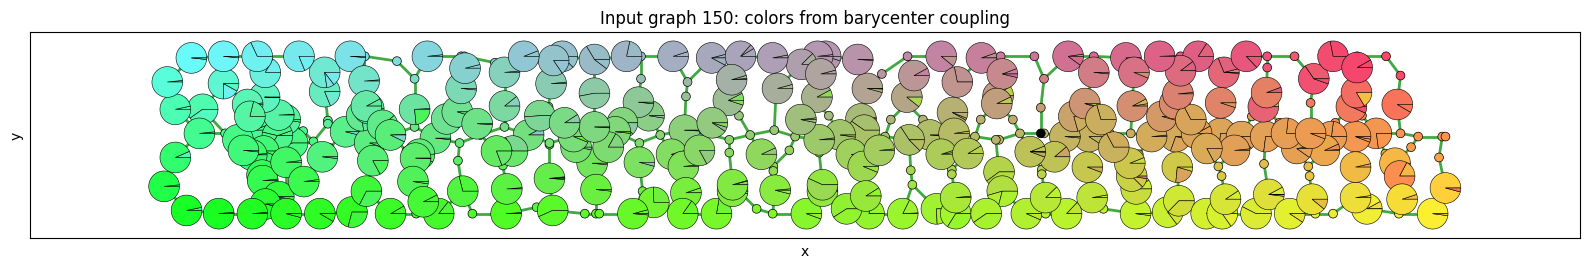

In [19]:
# Color transfer (2): map barycenter colors to each input graph via final PFGW couplings.

_p_bary = log["p"] if "p" in log else p
Ts_final = log["T"]

input_coupling_colors, input_use_pie = transfer_barycenter_colors_to_inputs(
    Ts_final,
    barycenter_node_colors,
    _p_bary,
)

for s, idx in enumerate(idx_list):
    draw_input_graph_coupling_colors(
        Gs[idx],
        nodes_list[idx],
        input_coupling_colors[s],
        input_use_pie[s],
        mesh_id=mesh_ids[idx],
    )


In [20]:
print(len(input_coupling_colors[2]))

372


## Experimental Reconstruction for Barycenter

We construct another pairwise relation matrix B_i for each input. This matrix resembles the idea of adjacency matrix, but it does not assign all pairs that are not directly connected to 0. Instead, for any pair of nodes whose shortest **unweighted** distance is r, their pairwise relation is "q^(r-1)" (0 < q < 1, default q=0.5). 

Then, the barycenter reconstruction will utilize the coupling between the barycenter and inputs, as well as this new pairwise relation matrix.

The idea is as follows:
- We initialize a new relation matrix for reconstruction (which does not replace C_center) to all 0 for the barycenter.
- For each 